# Basic Model for Archaic Population Substructure in Native Americans
In this first, basic model, the backbone of the Out of Africa > Beringia > America mirgation will be simulated, leaving complex demographic events aside for now.

Populations in this simulation:
* ANC: ancestral human population
* AFR: population that stays in Africa, child of ANC
* OOA: population that left Africa, child of ANC
* EAS: ancestors of East Asians, children of OOA
* BER: ancestors that will become Native Americans via Bringia, children of OOA
* NAT: the founding Native American population, children of BER

This simulation is not modeling migration between populations, multiple waves, introgressions, recent admixture. This will be added later.

In [32]:
# Libraries that will be needed 
import msprime

In [33]:
# Defining units of generations as 29 years per generation.
GEN_TIME = 29   # years per generation

# Converting from years to generations
def years_to_gens(years):
    return int(years / GEN_TIME)


# Setting up the times of population splits
T_OOA = years_to_gens(70_000)    # ANC -> AFR / OOA split
T_EAS_BER = years_to_gens(40_000)   # OOA -> EAS / BER split
T_NAT_FOUND = years_to_gens(16_000)   # BER -> NAT split
T_BOTTLENECK_START = years_to_gens(25_000)   # start of Beringian standstill bottleneck


## Demography object
it holds 
* all the populations that ever existed in the model
* populations sizes (Ne)
* all the events that connect populations over time

First populations are added with name and size. Populations existing today (NAT, EAS) are given the present-day Ne. Populatoins that existed in the past the size is the Ne they had right before any later size-change we define for them below. Sizes are, though, small, toy numbers chosen to keep this first simulation simple, it is not realistic estimates.

In [34]:
# ----------------------------------------------------------------
# DEMOGRAPHY OBJECT
# ----------------------------------------------------------------

# Adding all the populations that existed
demography  = msprime.Demography()
demography.add_population(name="ANC", initial_size=10_000, description="Deep ancestral population")
demography.add_population(name="AFR", initial_size=40_000, description="Population remaining in Africa")
demography.add_population(name="OOA", initial_size=2_000, description="Out of Africa population, bottlenecked")
demography.add_population(name="EAS", initial_size=10_000, description="Ancestors of East Asians")
demography.add_population(name="BER", initial_size=2_000, description="Ancestral Beringian population")
demography.add_population(name="NAT", initial_size=5_000, description="Founding Native American population")


Population(initial_size=5000, growth_rate=0, name='NAT', description='Founding Native American population', extra_metadata={}, default_sampling_time=None, initially_active=None, id=5)

## Demographic Events
To include splits and size changes (bottleneck).

In [35]:
#---------------------------------------------------------------
# Demographic Events
# --------------------------------------------------------------
# Add demographic events as splits and bottlenecks
#In msprime events are defined going backwards in time

# Native Americans are derived from Beringian
demography.add_population_split(time=T_NAT_FOUND, derived=["NAT"], ancestral = "BER")

# Bottleneck of the Beringian standstill defined as a change of Ne. We define the size before the bottleneck
demography.add_population_parameters_change(time=T_BOTTLENECK_START, population="BER", initial_size=800)

# EAS and BER descend from OOA populations
demography.add_population_split(time=T_EAS_BER, derived=["EAS", "BER"], ancestral="OOA")

# OOA and AFR descend from the deep ancestral population ANC
demography.add_population_split(time=T_OOA, derived=["OOA", "AFR"], ancestral="ANC")

# To sort all events according to time automatically (sanity check)
demography.sort_events()

# Print a table with the model specifications (sanity check, debug)
print(demography.debug())

DemographyDebugger
╠════════════════════════════════╗
║ Epoch[0]: [0, 551) generations ║
╠════════════════════════════════╝
╟    Populations (total=6 active=3)
║    ┌───────────────────────────────────────────────────────────┐
║    │     │     start│       end│growth_rate  │ AFR │ EAS │ NAT │
║    ├───────────────────────────────────────────────────────────┤
║    │  AFR│   10000.0│   10000.0│ 0           │  0  │  0  │  0  │
║    │  EAS│    5000.0│    5000.0│ 0           │  0  │  0  │  0  │
║    │  NAT│    5000.0│    5000.0│ 0           │  0  │  0  │  0  │
║    └───────────────────────────────────────────────────────────┘
╟    Events @ generation 551
║    ┌───────────────────────────────────────────────────────────────────────────┐
║    │  time│type        │parameters      │effect                                │
║    ├───────────────────────────────────────────────────────────────────────────┤
║    │   551│Population  │derived=[NAT],  │Moves all lineages from the 'NAT'     │
║    │    

## Ancestry simulation
Here, I sample individuals from present-day populations (either NAT, EAS or AFR). Individuals are diploid, so they contribute 2 genome copies. In this test, I sample from NAT (population of interest) and EAS (outgroup). Sample size is small for this first test.
Output: genealogical trees showing the coalescence among individuals (haploids).

In [36]:
ts = msprime.sim_ancestry(samples={"NAT": 10, "EAS":10},   # toy sample size of 50 diploids to reduce noise
                         demography=demography,
                         sequence_length=1_000_000,   # Toy genomic region, not full
                         recombination_rate=1e-8,
                         random_seed=42)    # Human recombination rate


## Mutations
Add neutral mutations onto the produced trees with a mutation rate, so it looks like real genetic variation data.

In [37]:
mts = msprime.sim_mutations(ts, rate=1.25e-8, random_seed=123)

### Sanity check
* NAT should show lower diversity than EAS because of the bottleneck
* 

In [38]:
print("\n--- Basic sanity checks ---")
print(f"Number of trees along the sequence: {mts.num_trees}")   # Number of trees for this tree sequence
print(f"Number of variable sites (mutations): {mts.num_sites}")   # Number of sites where a mutation occured. A tree can have several mutations

nat_pop = [p.id for p in demography.populations if p.name=="NAT"][0]   # gives the id for NAT population = 5
eas_pop = [p.id for p in demography.populations if p.name == "EAS"][0]   # gives the id for EAS population = 3

nat_samples = mts.samples(population=nat_pop)   # contains all the sampled haplotypes from NAT (20)
eas_samples = mts.samples(population=eas_pop)

print(f"Nucleotide diversity in NAT: {mts.diversity(sample_sets=nat_samples):.6f}")
print(f"Nucleotide diversity in EAS: {mts.diversity(sample_sets=eas_samples):.6f}")

# Save the tree sequence to reload later in msprime's native for efficient format
mts.dump("native_american_v1.trees")
print("\nSaved output to native_ameican_v1.trees")



--- Basic sanity checks ---
Number of trees along the sequence: 1058
Number of variable sites (mutations): 1665
Nucleotide diversity in NAT: 0.000333
Nucleotide diversity in EAS: 0.000403

Saved output to native_ameican_v1.trees


In [8]:
mts.samples(population=nat_pop)

array([ 0,  1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11, 12, 13, 14, 15, 16,
       17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33,
       34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50,
       51, 52, 53, 54, 55, 56, 57, 58, 59, 60, 61, 62, 63, 64, 65, 66, 67,
       68, 69, 70, 71, 72, 73, 74, 75, 76, 77, 78, 79, 80, 81, 82, 83, 84,
       85, 86, 87, 88, 89, 90, 91, 92, 93, 94, 95, 96, 97, 98, 99],
      dtype=int32)

## Genetic Statistics
Objective: compare the different versions as they get more complex.

The compute statistics will be calculated on the tree I generated for v1 (1Mb region with 10 diploid samples per population). 

* Nucleotide diversity (pi): variation inside one population. Influenced by Ne and drift.
* Divergence (Dxy): not-normalised variation between different populations.
* Fst: normalised differenciation comparing drift vs migration.
* Tajima's D: how far away it goes from neutral equilibrium.
* Site Frequency Spectrum: (visual) distribution of allele frequencies.
Calculations using tskit methods

In [22]:
# Import libraries to use
import json
import msprime
import numpy as np
import matplotlib.pyplot as plt

In [29]:
# List of sample node IDs (sample sets). One list per population of interest
# In this case I will compare NAT and EAS principally.
# This I already have in nat_samples and eas_samples
nat_pop_id = [p.id for p in demography.populations if p.name == "NAT"][0]
eas_pop_id = [p.id for p in demography.populations if p.name == "EAS"][0]
 
nat_samples = mts.samples(population=nat_pop_id)
eas_samples = mts.samples(population=eas_pop_id)
# -------------------------------------------------------
# NUCLEOTIDE DIVERSITY (within population diversity)
# -------------------------------------------------------
# This statistics calculates the average number of pairwise differences per site between two random haplotypes from the same population.
# The higher it is, the more the more genetic variation in this population.
# The smaller it is, implicates a strong effect of drift or bottleneck on reducing diversity.
# Expected: since NAT went through a bottleneck nd EAS did not, it is expected that NAT would present less diversity as population than EAS

pi_nat = mts.diversity(sample_sets=nat_samples)
pi_eas = mts.diversity(sample_sets=eas_samples)

print(f"Nucleotide diversity (pi)   NAT: {pi_nat:.6f}")
print(f"Nucleotide diversity (pi)   EAS: {pi_eas:.6f}")

# -------------------------------------------------------
# Divergence Dxy (between population variation)
# -------------------------------------------------------
# This is the average number of pairwise differences per site between one haplotype fom NAT and one from EAS
# This statistic is not normalised according to within population diversity.

dxy_nat_eas = mts.divergence(sample_sets=[nat_samples, eas_samples])

print(f"Divergence Dxy between NAT and EAS: {dxy_nat_eas:.6f}")

# -------------------------------------------------------
# Fst 
# -------------------------------------------------------
# Fst measures how much of the total genetic variation is explained by the differences between populations,
# relative to the variation within them. Therefore, this one is normalised.
# This statistics varies with migration, so we expect that in simulation v2 Fst would go down.
fst_nat_eas = mts.Fst(sample_sets=[nat_samples, eas_samples])

print(f"Fst between NAT and EAS: {fst_nat_eas:.6f}")

# -------------------------------------------------------
# TAJIMA'S D - neutrality /demographic-shape statistic
# -------------------------------------------------------
# negative Tajima's D → excess rare variants
# positive Tajima's D → excess intermediate-frequency variants
# D ≈ 0 → approximately neutral equilibrium SFS
tajd_nat = mts.Tajimas_D(sample_sets=nat_samples)
tajd_eas = mts.Tajimas_D(sample_sets=eas_samples)

print(f"Tajima's D for NAT: {tajd_nat:.6}")
print(f"Tajima's D for EAS: {tajd_eas:.6}")

# -------------------------------------------------------
# Site Frequency Spectrum SFS
# -------------------------------------------------------
# Its shape is informative: bottlenecks cause fewer rare allele so the distribution shifts the spectrum towards
# the center. Migration injects new allele variants so there would be more rare variants. This also happens with
# population growth.
# Here is computed the folded spectrum (not necessary to know which alleleis ancestral vs derived)
sfs_nat = mts.allele_frequency_spectrum(
    sample_sets=[nat_samples], polarised=False, span_normalise=False
)
sfs_eas = mts.allele_frequency_spectrum(
    sample_sets=[eas_samples], polarised=False, span_normalise=False
)



Nucleotide diversity (pi)   NAT: 0.000199
Nucleotide diversity (pi)   EAS: 0.000302
Divergence Dxy between NAT and EAS: 0.000302
Fst between NAT and EAS: 0.092663
Tajima's D for NAT: -0.139918
Tajima's D for EAS: 0.111988


## Results

In [30]:
results = {
    "model_version": "v1_no_migation",
    "description": "OOA -> EAS/BER split -> Beringian standstill -> NAT founding; no migration 50",
    "diversity_NAT": pi_nat,
    "diversity_eas": pi_eas,
    "divergence_NAT_EAS": dxy_nat_eas,
    "TajimasD_NAT": tajd_nat,
    "TajimasD_EAS": tajd_eas,
    # SFS are saved as plain lists so they are JSON-serialisable
    "SFS_NAT": sfs_nat.tolist(),
    "SFS_EAS": sfs_eas.tolist()
}

print("-------SUMMARY STATISTICS FOR v1--------")
print(f"Nucleotide diversity (pi)   NAT: {pi_nat:.6f}")
print(f"Nucleotide diversity (pi)   EAS: {pi_eas:.6f}")
print(f"Divergence (Dxy) NAT vs EAS:     {dxy_nat_eas:.6f}")
print(f"Fst NAT vs EAS:                  {fst_nat_eas:.4f}")
print(f"Tajima's D          NAT:         {tajd_nat:.4f}")
print(f"Tajima's D          EAS:         {tajd_eas:.4f}")
print(f"SFS NAT (folded, raw counts):    {sfs_nat}")
print(f"SFS EAS (folded, raw counts):    {sfs_eas}")

# ------------------------------------------------------------------------
# 10. SAVE RESULTS TO A LOG FILE FOR FUTURE MODEL-VERSION COMPARISON
# ------------------------------------------------------------------------
# We append results as one JSON object per line ("JSON Lines" format) to a
# single log file. Every time we run a new model version we re-run this same
# statistics script against it and append another line - this builds up a simple,
# easy-to-parse comparison table across versions without needing a database.
with open("model_comparison_stats.jsonl", "a") as f:
    f.write(json.dumps(results) + "\n")
 
print("\nAppended results to model_comparison_stats.jsonl")



-------SUMMARY STATISTICS FOR v1--------
Nucleotide diversity (pi)   NAT: 0.000199
Nucleotide diversity (pi)   EAS: 0.000302
Divergence (Dxy) NAT vs EAS:     0.000302
Fst NAT vs EAS:                  0.0927
Tajima's D          NAT:         -0.1399
Tajima's D          EAS:         0.1120
SFS NAT (folded, raw counts):    [1.0155e+03 1.9400e+02 8.1500e+01 7.1000e+01 7.1000e+01 6.7000e+01
 7.2000e+01 2.1000e+01 3.4500e+01 7.0000e+00 1.0500e+01 1.3000e+01
 2.4000e+01 3.5000e+01 8.0000e+00 7.5000e+00 1.0000e+00 2.6000e+01
 1.0000e+01 3.0000e+00 3.8000e+01 8.0000e+00 2.8000e+01 3.8000e+01
 3.1500e+01 1.7000e+01 1.8000e+01 8.0000e+00 1.3000e+01 1.1000e+01
 1.4000e+01 7.0000e+00 1.1000e+01 0.0000e+00 6.0000e+00 1.3000e+01
 8.0000e+00 0.0000e+00 1.6000e+01 1.5000e+00 3.0000e+00 0.0000e+00
 1.0000e+00 0.0000e+00 1.1000e+01 6.0000e+00 0.0000e+00 1.0000e+00
 3.0000e+00 3.0000e+00 1.0000e+00 0.0000e+00 0.0000e+00 0.0000e+00
 0.0000e+00 0.0000e+00 0.0000e+00 0.0000e+00 0.0000e+00 0.0000e+00
 0.0000e+

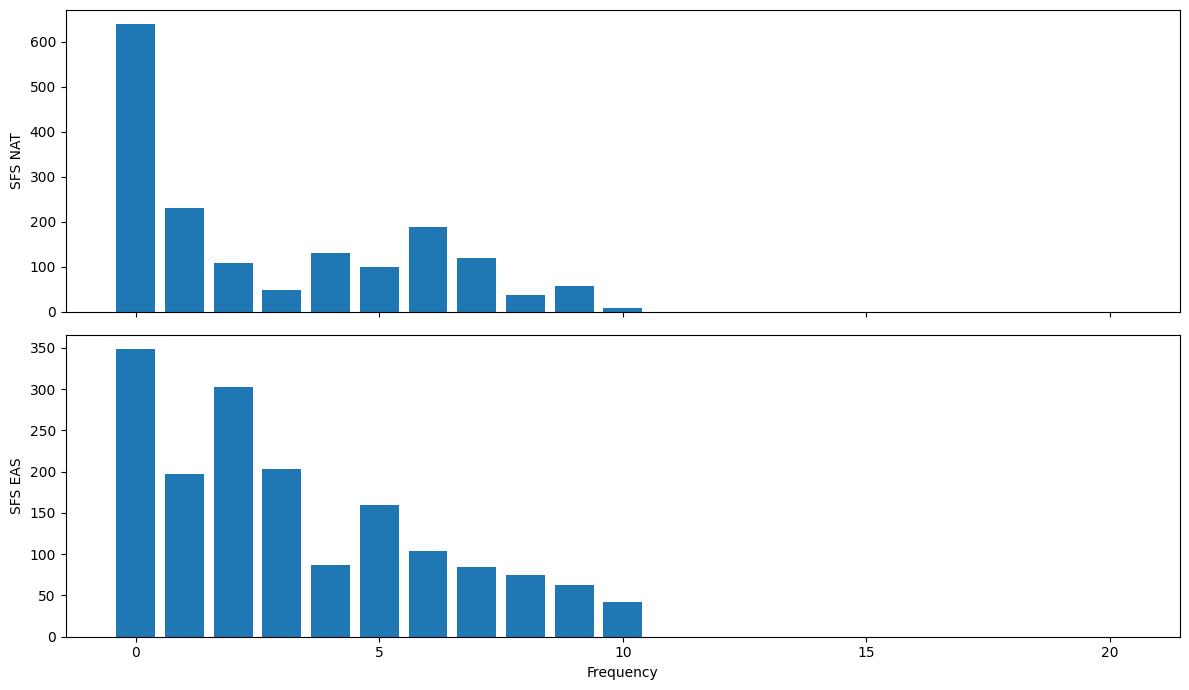

In [36]:
# Plotting SFS 
fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True)

axes[0].bar(np.arange(len(sfs_nat)), sfs_nat)
axes[0].set_ylabel('SFS NAT')

axes[1].bar(np.arange(len(sfs_eas)), sfs_eas)
axes[1].set_ylabel('SFS EAS')
axes[1].set_xlabel('Frequency')

plt.tight_layout()
plt.show()

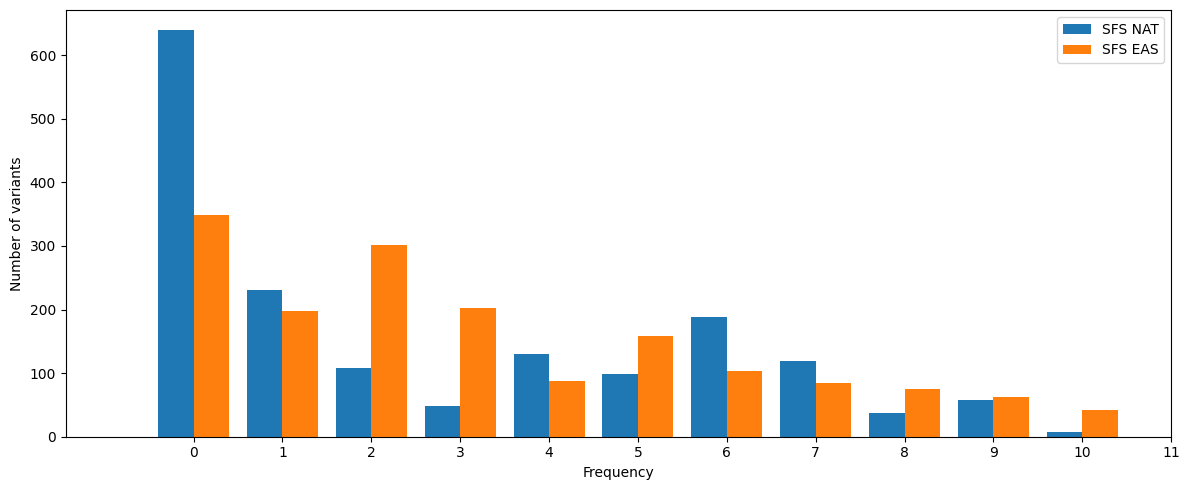

In [4]:
# Plotting SFS

x = np.arange(len(sfs_nat))
width = 0.4

plt.figure(figsize=(12, 5))

plt.bar(x - width/2, sfs_nat, width, label='SFS NAT')
plt.bar(x + width/2, sfs_eas, width, label='SFS EAS')

plt.xlabel('Frequency')
plt.ylabel('Number of variants')
plt.xticks(x)
plt.xlim(right=11)
plt.legend()
plt.tight_layout()
plt.savefig("SFS_nat_eas_10")

plt.show()


## Checking code


In [39]:
import msprime, tskit, sys
print("msprime:", msprime.__version__)
print("tskit:", tskit.__version__)
print("python:", sys.version)

msprime: 1.4.0
tskit: 1.0.1
python: 3.10.20 | packaged by conda-forge | (main, Mar  5 2026, 16:59:46) [Clang 19.1.7 ]


In [6]:
# Import libraries to use
import json
import msprime
import numpy as np
import matplotlib.pyplot as plt

# Defining units of generations as 29 years per generation.
GEN_TIME = 29   # years per generation

# Converting from years to generations
def years_to_gens(years):
    return int(years / GEN_TIME)


# Setting up the times of population splits
T_OOA = years_to_gens(70_000)    # ANC -> AFR / OOA split  # 50_000 according to Hallett et al., 2025
T_EAS_BER = years_to_gens(40_000)   # OOA -> EAS / BER split
T_NAT_FOUND = years_to_gens(16_000)   # BER -> NAT split
T_BOTTLENECK_START = years_to_gens(25_000)   # start of Beringian standstill bottleneck

# ----------------------------------------------------------------
# DEMOGRAPHY OBJECT
# ----------------------------------------------------------------

# Adding all the populations that existed
demography  = msprime.Demography()
demography.add_population(name="ANC", initial_size=10_000, description="Deep ancestral population")
demography.add_population(name="AFR", initial_size=40_000, description="Population remaining in Africa")
demography.add_population(name="OOA", initial_size=2_000, description="Out of Africa population, bottlenecked")
demography.add_population(name="EAS", initial_size=10_000, description="Ancestors of East Asians")
demography.add_population(name="BER", initial_size=2_000, description="Ancestral Beringian population")
demography.add_population(name="NAT", initial_size=5_000, description="Founding Native American population")

#---------------------------------------------------------------
# Demographic Events
# --------------------------------------------------------------
# Add demographic events as splits and bottlenecks
#In msprime events are defined going backwards in time

# Native Americans are derived from Beringian
demography.add_population_split(time=T_NAT_FOUND, derived=["NAT"], ancestral = "BER")

# Bottleneck of the Beringian standstill defined as a change of Ne. We define the size before the bottleneck
demography.add_population_parameters_change(time=T_BOTTLENECK_START, population="BER", initial_size=800)

# EAS and BER descend from OOA populations
demography.add_population_split(time=T_EAS_BER, derived=["EAS", "BER"], ancestral="OOA")

# OOA and AFR descend from the deep ancestral population ANC
demography.add_population_split(time=T_OOA, derived=["OOA", "AFR"], ancestral="ANC")

# To sort all events according to time automatically (sanity check)
demography.sort_events()

# Print a table with the model specifications (sanity check, debug)
print(demography.debug())

ts = msprime.sim_ancestry(samples={"NAT": 80, "EAS":80},   # toy sample size of 50 diploids to reduce noise
                         demography=demography,
                         sequence_length=1_000_000,   # Toy genomic region, not full
                         recombination_rate=1e-8,
                         random_seed=42)    # Human recombination rate

mts = msprime.sim_mutations(ts, rate=1.25e-8, random_seed=123)

# List of sample node IDs (sample sets). One list per population of interest
# In this case I will compare NAT and EAS principally.
# This I already have in nat_samples and eas_samples
nat_pop_id = [p.id for p in demography.populations if p.name == "NAT"][0]
eas_pop_id = [p.id for p in demography.populations if p.name == "EAS"][0]
 
nat_samples = mts.samples(population=nat_pop_id)
eas_samples = mts.samples(population=eas_pop_id)
# -------------------------------------------------------
# NUCLEOTIDE DIVERSITY (within population diversity)
# -------------------------------------------------------
# This statistics calculates the average number of pairwise differences per site between two random haplotypes from the same population.
# The higher it is, the more the more genetic variation in this population.
# The smaller it is, implicates a strong effect of drift or bottleneck on reducing diversity.
# Expected: since NAT went through a bottleneck nd EAS did not, it is expected that NAT would present less diversity as population than EAS

pi_nat = mts.diversity(sample_sets=nat_samples)
pi_eas = mts.diversity(sample_sets=eas_samples)

print(f"Nucleotide diversity (pi)   NAT: {pi_nat:.6f}")
print(f"Nucleotide diversity (pi)   EAS: {pi_eas:.6f}")

# -------------------------------------------------------
# Divergence Dxy (between population variation)
# -------------------------------------------------------
# This is the average number of pairwise differences per site between one haplotype fom NAT and one from EAS
# This statistic is not normalised according to within population diversity.

dxy_nat_eas = mts.divergence(sample_sets=[nat_samples, eas_samples])

print(f"Divergence Dxy between NAT and EAS: {dxy_nat_eas:.6f}")

# -------------------------------------------------------
# Fst 
# -------------------------------------------------------
# Fst measures how much of the total genetic variation is explained by the differences between populations,
# relative to the variation within them. Therefore, this one is normalised.
# This statistics varies with migration, so we expect that in simulation v2 Fst would go down.
fst_nat_eas = mts.Fst(sample_sets=[nat_samples, eas_samples])

print(f"Fst between NAT and EAS: {fst_nat_eas:.6f}")

# -------------------------------------------------------
# TAJIMA'S D - neutrality /demographic-shape statistic
# -------------------------------------------------------
# negative Tajima's D → excess rare variants
# positive Tajima's D → excess intermediate-frequency variants
# D ≈ 0 → approximately neutral equilibrium SFS
tajd_nat = mts.Tajimas_D(sample_sets=nat_samples)
tajd_eas = mts.Tajimas_D(sample_sets=eas_samples)

print(f"Tajima's D for NAT: {tajd_nat:.6}")
print(f"Tajima's D for EAS: {tajd_eas:.6}")

# -------------------------------------------------------
# Site Frequency Spectrum SFS
# -------------------------------------------------------
# Its shape is informative: bottlenecks cause fewer rare allele so the distribution shifts the spectrum towards
# the center. Migration injects new allele variants so there would be more rare variants. This also happens with
# population growth.
# Here is computed the folded spectrum (not necessary to know which alleleis ancestral vs derived)
sfs_nat = mts.allele_frequency_spectrum(
    sample_sets=[nat_samples], polarised=False, span_normalise=False
)
sfs_eas = mts.allele_frequency_spectrum(
    sample_sets=[eas_samples], polarised=False, span_normalise=False
)



DemographyDebugger
╠════════════════════════════════╗
║ Epoch[0]: [0, 551) generations ║
╠════════════════════════════════╝
╟    Populations (total=6 active=3)
║    ┌───────────────────────────────────────────────────────────┐
║    │     │     start│       end│growth_rate  │ AFR │ EAS │ NAT │
║    ├───────────────────────────────────────────────────────────┤
║    │  AFR│   10000.0│   10000.0│ 0           │  0  │  0  │  0  │
║    │  EAS│    5000.0│    5000.0│ 0           │  0  │  0  │  0  │
║    │  NAT│    5000.0│    5000.0│ 0           │  0  │  0  │  0  │
║    └───────────────────────────────────────────────────────────┘
╟    Events @ generation 551
║    ┌───────────────────────────────────────────────────────────────────────────┐
║    │  time│type        │parameters      │effect                                │
║    ├───────────────────────────────────────────────────────────────────────────┤
║    │   551│Population  │derived=[NAT],  │Moves all lineages from the 'NAT'     │
║    │    